# Can AI help deliver social benefits, or only make things worse?

Companion notebook to my article on poverty in Spain and AI. Two parts:

1. **Real public figures** (Eurostat, INE, AIReF) that show the *delivery gap*.
2. **A synthetic simulation** (clearly not real data) with two experiments:
   - A: using a model to find eligible households that never applied.
   - B: what happens when a risk model learns from biased audit history (the Dutch childcare benefit case), and how an audit and a simple fix change the picture.

Everything in part 2 is invented data with stated assumptions. It illustrates mechanisms; it does not measure Spain.

## 1. Real figures: the delivery gap

Sources: Eurostat news item of 30 April 2026 and INE ECV 2025 (AROPE, unexpected expenses); AIReF report of July 2025 on the Ingreso Minimo Vital (non-take-up).

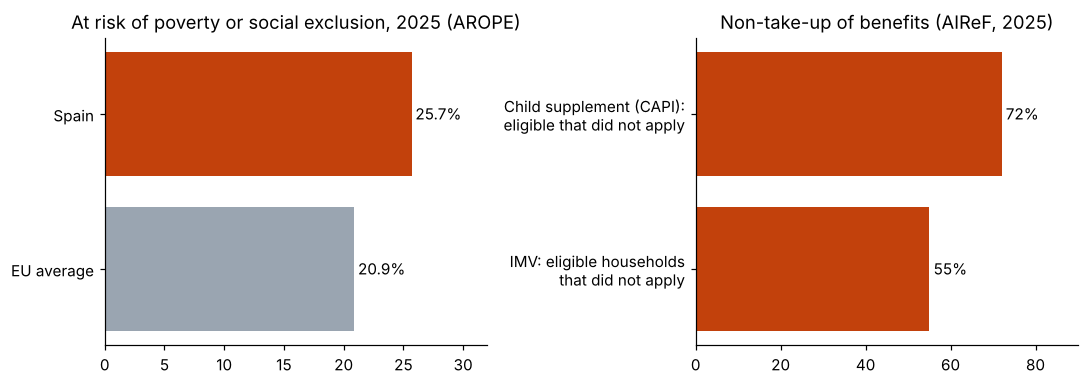

Spain: 36.4% of the population could not face an unexpected expense (INE ECV 2025).


In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'font.size':10})

fig, ax = plt.subplots(1,2, figsize=(10,3.6))
ax[0].barh(['EU average','Spain'], [20.9, 25.7], color=['#9aa5b1','#c2410c'])
for i,v in enumerate([20.9,25.7]): ax[0].text(v+0.3,i,f'{v}%',va='center')
ax[0].set_title('At risk of poverty or social exclusion, 2025 (AROPE)'); ax[0].set_xlim(0,32)

labels=['IMV: eligible households\nthat did not apply','Child supplement (CAPI):\neligible that did not apply']
vals=[55,72]
ax[1].barh(labels, vals, color='#c2410c')
for i,v in enumerate(vals): ax[1].text(v+1,i,f'{v}%',va='center')
ax[1].set_title('Non-take-up of benefits (AIReF, 2025)'); ax[1].set_xlim(0,90)
plt.tight_layout(); plt.show()
print('Spain: 36.4% of the population could not face an unexpected expense (INE ECV 2025).')

## 2. Simulation setup (synthetic data)

Assumptions, all invented for illustration:
- 60,000 households; a household is *eligible* if its income is below 70% of a poverty line.
- Non-take-up is driven by friction (limited digital access, administrative effort), calibrated so that **55% of eligible households do not apply**, matching the AIReF headline.
- The administration only sees *noisy* records (income measured with error, some missing).

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(42)
N = 60_000

ratio = rng.lognormal(mean=0.25, sigma=0.55, size=N)          # income / poverty line
foreign = rng.random(N) < 0.12
ratio = np.where(foreign, ratio*0.9, ratio)                    # slightly lower incomes in this group
children = rng.poisson(0.6, N)
low = ratio < 0.7
digital = rng.random(N) < np.where(low, 0.62, 0.90)
eligible = low

# calibrate intercept so that take-up among eligible = 45%
def takeup_p(b):
    z = b + 1.2*digital + 0.3*(children>0)
    return 1/(1+np.exp(-z))
lo, hi = -5, 5
for _ in range(60):
    mid=(lo+hi)/2
    if takeup_p(mid)[eligible].mean() < 0.45: lo=mid
    else: hi=mid
p = takeup_p(mid)
applied = eligible & (rng.random(N) < p)

# what the administration observes (noisy)
obs_ratio = ratio * rng.lognormal(0, 0.25, N)
missing = rng.random(N) < 0.15
obs_ratio = np.where(missing, np.nanmedian(obs_ratio), obs_ratio)
registered_child = children>0

df = pd.DataFrame(dict(obs_ratio=obs_ratio, missing=missing.astype(int), children=children,
                       registered_child=registered_child.astype(int), digital=digital.astype(int),
                       foreign=foreign.astype(int), eligible=eligible, applied=applied))
print(f"eligible: {eligible.sum()}  applied: {applied.sum()}  non-take-up among eligible: {1-applied[eligible].mean():.1%}")

eligible: 8402  applied: 3753  non-take-up among eligible: 55.3%


## Experiment A: find eligible households that never applied

The model is trained **only on households that applied** (their eligibility was verified), then scores everyone who did not apply. This is the realistic setup, and it carries a selection bias: applicants are more digital than non-applicants.

We compare three outreach strategies with the same budget of contacts: random, a simple rule (income below the line), and the model.

                    strategy  eligible_found  precision
             Random outreach             166     0.0830
Rule: lowest recorded income            1700     0.8500
                       Model            1703     0.8515

AUC on non-applicants (ground truth known only in the simulation): 0.932
Eligible non-applicants in total: 4649


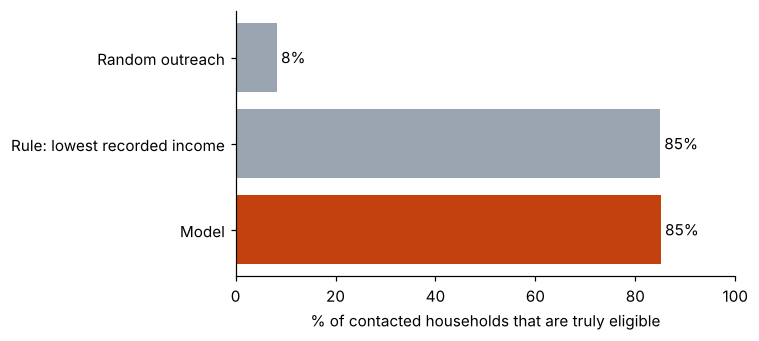

In [3]:
feats = ['obs_ratio','missing','children','registered_child']   # no nationality, no digital access
train = df[df.applied]
# applicants are all eligible by construction -> need negatives: use households with verified ineligible decisions
# (in reality: past rejected applications). Simulate 6,000 rejected applications from non-eligible households.
rejected = df[(~df.eligible)].sample(6000, random_state=1)
tr = pd.concat([train, rejected])
y = tr.eligible.astype(int)
model = GradientBoostingClassifier(random_state=0).fit(tr[feats], y)

pool = df[~df.applied]                      # who the administration could contact
scores = model.predict_proba(pool[feats])[:,1]
K = 2000
top = pool.assign(s=scores).nlargest(K,'s')
rand = pool.sample(K, random_state=3)
rule = pool.assign(r=-pool.obs_ratio).nlargest(K,'r')

res = pd.DataFrame({'strategy':['Random outreach','Rule: lowest recorded income','Model'],
                    'eligible_found':[rand.eligible.sum(), rule.eligible.sum(), top.eligible.sum()]})
res['precision'] = res.eligible_found/K
print(res.to_string(index=False))
print('\nAUC on non-applicants (ground truth known only in the simulation):', round(roc_auc_score(pool.eligible, scores),3))
print('Eligible non-applicants in total:', int(pool.eligible.sum()))

fig, ax = plt.subplots(figsize=(7,3.2))
ax.barh(res.strategy[::-1], res.precision[::-1]*100, color=['#c2410c','#9aa5b1','#9aa5b1'])
for i,v in enumerate(res.precision[::-1]*100): ax.text(v+0.8,i,f'{v:.0f}%',va='center')
ax.set_xlabel('% of contacted households that are truly eligible'); ax.set_xlim(0,100)
plt.tight_layout(); plt.show()

In [4]:
# Who does the model reach? Check digital access, the group most affected by friction.
for name, grp in [('Model',top),('Random',rand)]:
    print(f"{name}: share without digital access among contacted eligible = "
          f"{(grp[grp.eligible].digital==0).mean():.1%}")
print("Among ALL eligible non-applicants:", f"{(pool[pool.eligible].digital==0).mean():.1%}")
conv = 0.60   # ASSUMPTION: share of contacted eligible households that end up applying
gain = top.eligible.sum()*conv
print(f"\nIf {conv:.0%} of contacted eligible households apply, take-up rises by about "
      f"{gain/eligible.sum()*100:.1f} percentage points for {K} contacts.")

Model: share without digital access among contacted eligible = 49.3%
Random: share without digital access among contacted eligible = 49.4%
Among ALL eligible non-applicants: 49.0%

If 60% of contacted eligible households apply, take-up rises by about 12.2 percentage points for 2000 contacts.


**Reading Experiment A.** A model beats random outreach by a wide margin, but a simple rule on recorded income already does most of the work. The honest message is not "AI is magic": the value is in *using data the administration already holds* to reach people proactively, and a model matters most when records are noisy or incomplete. The channel also matters: if outreach is digital-only, the households with the most friction are still missed.

## Experiment B: a risk model learns from biased history

Now the Dutch scenario. Among applicants, **true fraud depends only on income, never on group** (by construction). But historically, audits targeted one group twice as often (20% audited vs 10%), so the *recorded* fraud labels are biased. We train a risk model on those labels and look at who it flags.

In [5]:
rng = np.random.default_rng(7)
M = 40_000
f = rng.random(M) < 0.12
proxy = np.where(f, rng.random(M)<0.7, rng.random(M)<0.1)        # e.g. language / region correlated with the group
ratio2 = rng.lognormal(-0.2,0.5,M)
kids = rng.poisson(0.8,M)
true_fraud = rng.random(M) < np.where(ratio2<0.8, 0.045, 0.02)   # depends on income only; same in both groups given income
audited = rng.random(M) < np.where(f, 0.20, 0.10)                 # biased audit history: group audited twice as often
label = true_fraud & audited
X_all = pd.DataFrame(dict(income=ratio2, kids=kids, foreign=f.astype(int), proxy=proxy.astype(int)))

def flag_stats(cols, y, name, mask=None):
    m = LogisticRegression(max_iter=1000).fit(X_all[cols] if mask is None else X_all.loc[mask,cols],
                                              y if mask is None else y[mask])
    s = m.predict_proba(X_all[cols])[:,1]
    flagged = s >= np.quantile(s, 0.80)                           # flag the top 20%
    r_for, r_nat = flagged[f].mean(), flagged[~f].mean()
    return dict(model=name, flagged_foreign=r_for, flagged_national=r_nat, ratio=r_for/r_nat,
                true_fraud_in_flagged=true_fraud[flagged].mean(),
                true_fraud_foreign=true_fraud[f].mean(), true_fraud_national=true_fraud[~f].mean())

rows = [
  flag_stats(['income','kids','foreign','proxy'], label, 'B1: biased labels, nationality included'),
  flag_stats(['income','kids','proxy'],           label, 'B2: biased labels, nationality removed (proxy stays)'),
]
# mitigation: train on a RANDOM audit sample (unbiased labels), no nationality, no proxy
rand_mask = rng.random(M) < 0.15
rand_label = true_fraud
rows.append(flag_stats(['income','kids'], rand_label, 'B3: random-audit labels, no nationality, no proxy', mask=rand_mask))
out = pd.DataFrame(rows)
pd.options.display.float_format = '{:.3f}'.format
print(out.to_string(index=False))

                                               model  flagged_foreign  flagged_national  ratio  true_fraud_in_flagged  true_fraud_foreign  true_fraud_national
             B1: biased labels, nationality included            0.996             0.093 10.692                  0.034               0.031                0.032
B2: biased labels, nationality removed (proxy stays)            0.568             0.151  3.771                  0.041               0.031                0.032
   B3: random-audit labels, no nationality, no proxy            0.210             0.199  1.060                  0.044               0.031                0.032


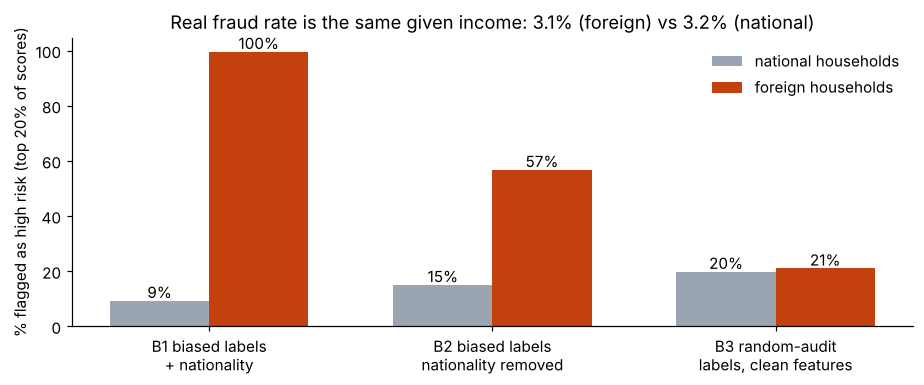

In [6]:
fig, ax = plt.subplots(figsize=(8.5,3.6))
lab = ['B1 biased labels\n+ nationality','B2 biased labels\nnationality removed','B3 random-audit\nlabels, clean features']
x = np.arange(3); w=0.35
b1=ax.bar(x-w/2, out.flagged_national*100, w, label='national households', color='#9aa5b1')
b2=ax.bar(x+w/2, out.flagged_foreign*100, w, label='foreign households', color='#c2410c')
for r in list(b1)+list(b2): ax.text(r.get_x()+r.get_width()/2, r.get_height()+1, f'{r.get_height():.0f}%', ha='center')
ax.set_xticks(x); ax.set_xticklabels(lab); ax.set_ylabel('% flagged as high risk (top 20% of scores)')
ax.set_title(f"Real fraud rate is the same given income: {out.true_fraud_foreign[0]:.1%} (foreign) vs {out.true_fraud_national[0]:.1%} (national)")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Reading Experiment B.**
- B1 reproduces the Dutch mechanism: the model learns the bias in the history and flags one group several times more often, even though real fraud is identical.
- B2 shows that *deleting the sensitive column is not enough*: correlated variables (a proxy) carry the same signal.
- B3 shows a practical fix: train on a small **random audit sample** instead of on who happened to be audited, and keep sensitive and proxy features out. Parity is restored.

The point for governance is the audit itself: the disparity above is invisible unless someone measures flag rates **by group**, which is exactly what the EU AI Act (high-risk systems for public benefits) and the Spanish BOSCO ruling push towards: documentation, logs and independent access.

## Caveats

- Synthetic data. Real administrative data is messier and the effect sizes here are set by my assumptions.
- The conversion rate after outreach (60%) is an assumption, not an empirical finding.
- A model only decides *who to contact or review*. In a real deployment a person decides, and the affected household can ask for an explanation and appeal.

Code and data generation are in this notebook, so every number above can be reproduced with the fixed random seeds.